# 02 — Simple stellar populations with FaSTAR

*Lecture 1: stellar populations and the IMF*

A **simple stellar population (SSP)** is a group of stars born at the same time with the same chemistry. Its spectrum is

$$F_\lambda(t, Z) = \int_{m_{\min}}^{m_{\rm TO}(t)} \xi(m)\, f_\lambda\big(m, t, Z\big)\, dm ,$$

i.e. the IMF $\xi(m)$ weights the spectra $f_\lambda$ of the stars that are still alive on the isochrone.

We use **FaSTAR** (Martín-Navarro et al. 2026, A&A 711, A282 and A283), a fast, differentiable SSP code:
`pip install fastar-astro` — docs: https://fastar.readthedocs.io

Valid range: ages 0.02–14 Gyr, [M/H] from −2.5 to +0.3. The first call takes ~10 s (it loads a neural network); afterwards a spectrum takes ~1 s.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # makes the small 'stellarpops' package importable
import numpy as np
import matplotlib.pyplot as plt
from stellarpops.style import use_slide_style
use_slide_style(dark=False, scale=0.7)       # dark=True gives the lecture-slide look

from fastar import IntegratedSSPSynthesizer, SemiresolvedSSPSynthesizer, imf
from stellarpops.remnants import living_plus_remnant_mass
from stellarpops import kroupa_xi

ssp = IntegratedSSPSynthesizer(imf_function=imf.kroupa)
wave = np.array(ssp.wave)

def norm(s, lo=5400, hi=5600):
    s = np.array(s); sel = (wave > lo) & (wave < hi)
    return s / np.median(s[sel])

## 1. Age
Same IMF, same metallicity, different ages. Prediction first: what happens to the blue part of the spectrum and to the total brightness?

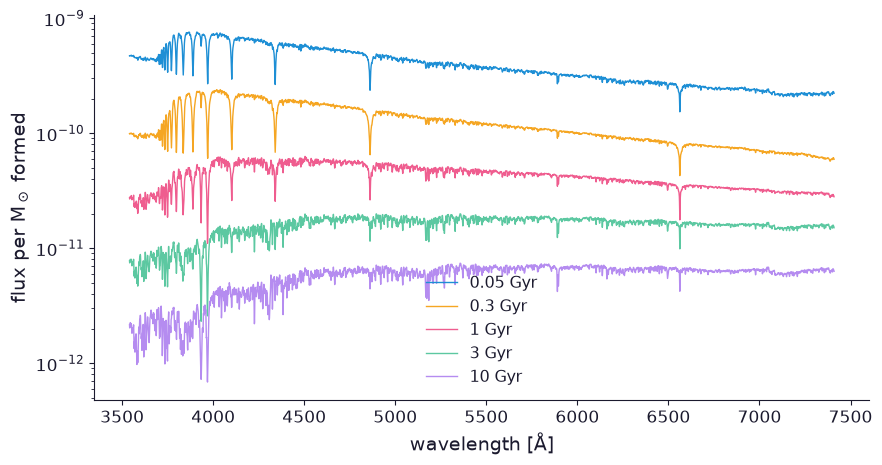

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
for age in [0.05, 0.3, 1, 3, 10]:
    ax.plot(wave, np.array(ssp.synthesize(age=age, met=0.0)), lw=1, label=f'{age} Gyr')
ax.set_yscale('log'); ax.set_xlabel('wavelength [Å]'); ax.set_ylabel(r'flux per M$_\odot$ formed'); ax.legend()

## 2. Mass-to-light ratio
FaSTAR gives the luminosity per solar mass *formed*. We add up the mass still in living stars and remnants (white dwarfs, neutron stars, black holes) to get the usual $M_*/L_V$.

Text(0, 0.5, '$M_*/L_V$ (stars + remnants)')

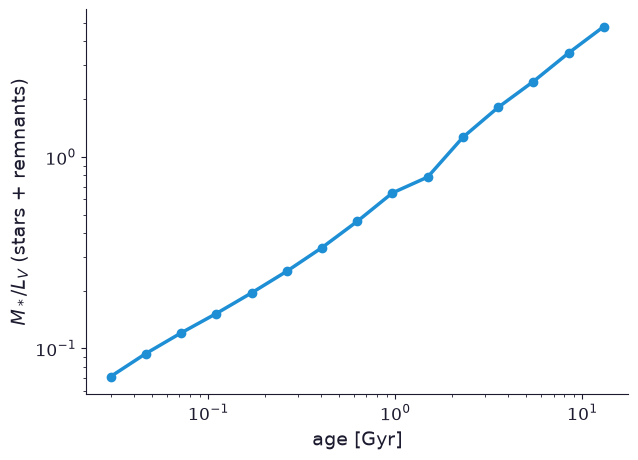

In [3]:
ages = np.geomspace(0.03, 13, 15)
ml = [float(ssp.mass_to_light_ratio(age=a, met=0.0)['total']) * living_plus_remnant_mass(a, kroupa_xi) for a in ages]
plt.figure(figsize=(7, 5)); plt.loglog(ages, ml, 'o-')
plt.xlabel('age [Gyr]'); plt.ylabel(r'$M_*/L_V$ (stars + remnants)')

**Question:** you measure the V-band luminosity of a galaxy. How wrong is its stellar mass if you assume 10 Gyr but it is really 1 Gyr old?

## 3. Metallicity
Same age (10 Gyr), different [M/H]. Look at the Mg b lines (~5175 Å) and the overall slope.

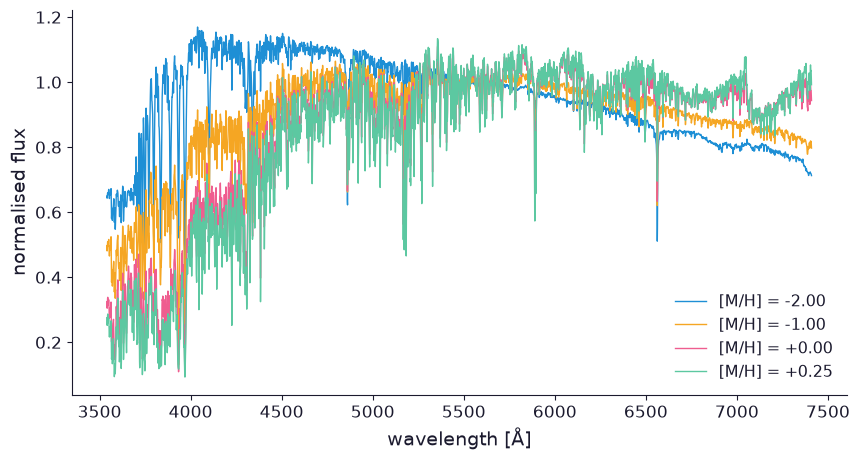

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for met in [-2.0, -1.0, 0.0, 0.25]:
    ax.plot(wave, norm(ssp.synthesize(age=10.0, met=met)), lw=1, label=f'[M/H] = {met:+.2f}')
ax.set_xlabel('wavelength [Å]'); ax.set_ylabel('normalised flux'); ax.legend()

**Your turn — the age–metallicity degeneracy:** find a *younger, more metal-rich* population whose spectrum shape (normalised) looks similar to a 10 Gyr, [M/H] = −0.5 one. Worthey's (1994) "3/2 rule": a population 3× older looks almost the same as one 2× more metal-rich, i.e. Δlog t ≈ −(3/2) Δlog Z along lines of constant colour.

In [5]:
# your code here

## 4. The IMF
Now vary the slope of a single power law (Salpeter = 2.35). Compare the spectra *and* the mass-to-light ratios.

Text(0, 0.5, '$M_*/L_V$ at 10 Gyr')

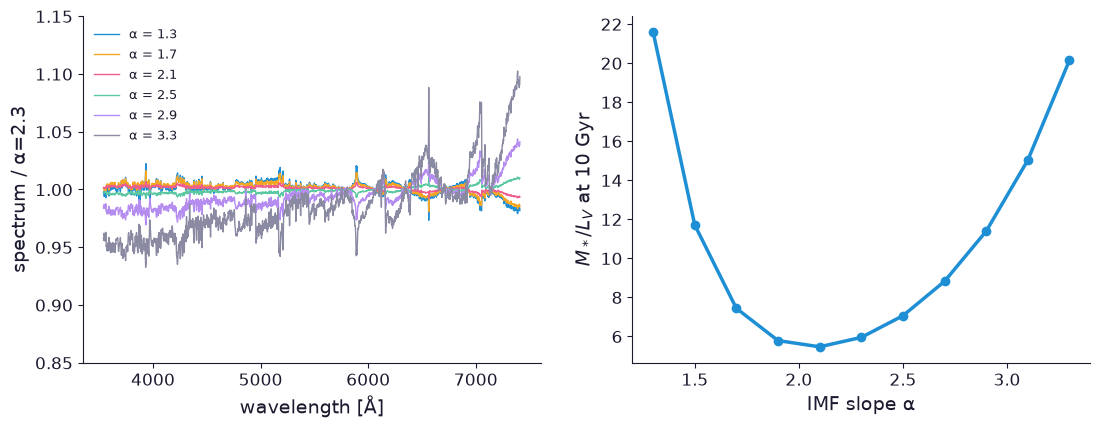

In [6]:
spl = IntegratedSSPSynthesizer(imf_function=imf.single_power_law)
alphas = np.linspace(1.3, 3.3, 11)
ml_a, specs = [], []
for a in alphas:
    p = {'alpha': float(a)}
    specs.append(norm(spl.synthesize(age=10.0, met=0.0, imf_params=p), 6000, 6200))
    xi = lambda m, a=a: np.asarray(m) ** (-a)
    ml_a.append(float(spl.mass_to_light_ratio(age=10.0, met=0.0, imf_params=p)['total']) * living_plus_remnant_mass(10.0, xi))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ref = specs[5]   # alpha = 2.3
for a, s in zip(alphas[::2], specs[::2]):
    ax1.plot(wave, s / ref, lw=1, label=f'α = {a:.1f}')
ax1.set_ylim(0.85, 1.15); ax1.set_xlabel('wavelength [Å]'); ax1.set_ylabel('spectrum / α=2.3'); ax1.legend(fontsize=9)
ax2.plot(alphas, ml_a, 'o-'); ax2.set_xlabel('IMF slope α'); ax2.set_ylabel(r'$M_*/L_V$ at 10 Gyr')

**Questions**
1. Why is the M/L high for *both* very flat and very steep IMFs? (Which kind of object carries the mass in each case?)
2. The spectrum changes by only a few per cent. Which features change? Why are Na D and TiO sensitive to low-mass dwarfs?
3. Compare: changing α from 2.3 to 3.0 changes the spectrum by ~2–5 %, but the mass by a factor ~2. What does this mean for measuring galaxy masses?

## 5. Few stars: stochastic sampling
A real star cluster or a small patch of a galaxy has a *finite* number of stars. FaSTAR's semi-resolved models draw them randomly. (Memory grows with the number of stars: keep it ≤ 5000 on a laptop.)

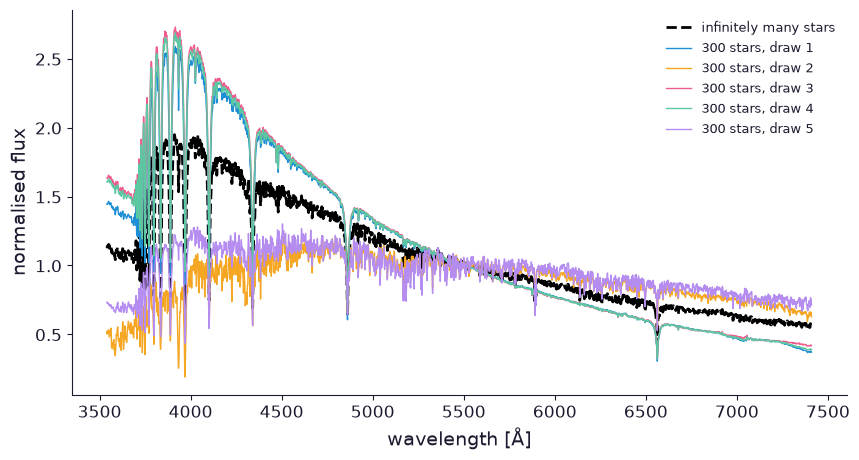

In [7]:
import jax
semi = SemiresolvedSSPSynthesizer(imf_function=imf.kroupa)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(wave, norm(ssp.synthesize(age=0.1, met=0.0)), 'k--', lw=2, label='infinitely many stars')
for i, key in enumerate(jax.random.split(jax.random.PRNGKey(0), 5)):
    s, mass = semi.synthesize(age=0.1, met=0.0, num_stars=300, key=key)
    ax.plot(wave, norm(s), lw=1, label=f'300 stars, draw {i+1}')
ax.set_xlabel('wavelength [Å]'); ax.set_ylabel('normalised flux'); ax.legend(fontsize=9)

**Your turn:** repeat for 30 and 3000 stars, and for an old (10 Gyr) population. When can you trust an SSP fit to a small cluster?